we are going to evaluate quantum circuits using circuit depth, gate count, total instructions, and measurement results. The goal is to understand that a quantum circuit should be assessed not only by the output it produces, but also by how complex the circuit is to execute.

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

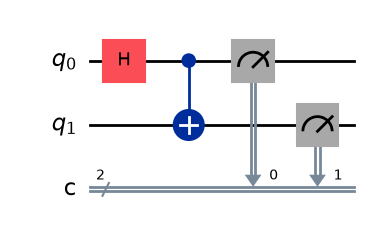

In [3]:
simple_circuit = QuantumCircuit(2, 2)

simple_circuit.h(0)
simple_circuit.cx(0, 1)

simple_circuit.measure([0, 1], [0, 1])

simple_circuit.draw("mpl")

In [4]:
simple_depth = simple_circuit.depth()

print(
    f"Simple circuit depth: "
    f"{simple_depth}"
)

Simple circuit depth: 3


In [5]:
simple_gate_counts = simple_circuit.count_ops()

print("Operations:")
print(simple_gate_counts)

Operations:
OrderedDict({'measure': 2, 'h': 1, 'cx': 1})


In [6]:
print(
    f"Total instructions: "
    f"{simple_circuit.size()}"
)

print(
    f"Number of qubits: "
    f"{simple_circuit.num_qubits}"
)

print(
    f"Number of classical bits: "
    f"{simple_circuit.num_clbits}"
)

print(
    f"Circuit depth: "
    f"{simple_circuit.depth()}"
)

Total instructions: 4
Number of qubits: 2
Number of classical bits: 2
Circuit depth: 3


In [7]:
simulator = AerSimulator()

In [8]:
simple_result = simulator.run(
    simple_circuit,
    shots=2000
).result()

simple_counts = simple_result.get_counts()

print(simple_counts)

{'00': 997, '11': 1003}


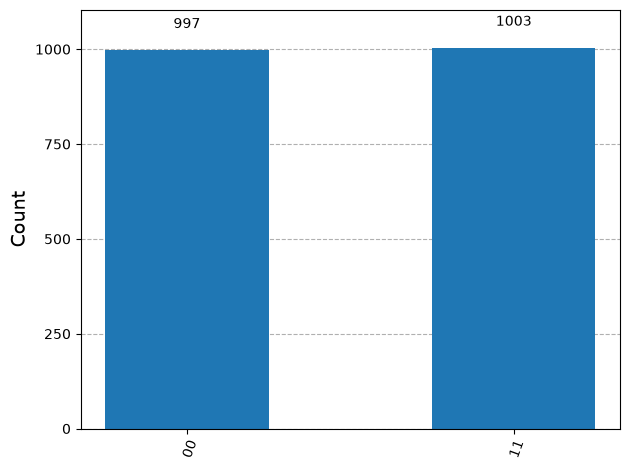

In [9]:
plot_histogram(simple_counts)

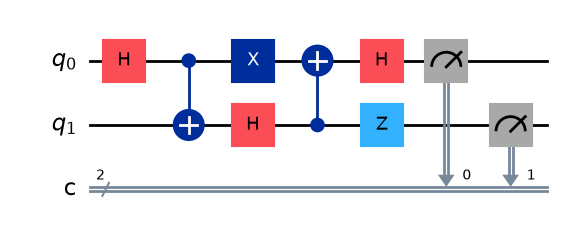

In [10]:
deep_circuit = QuantumCircuit(2, 2)

deep_circuit.h(0)
deep_circuit.cx(0, 1)

deep_circuit.x(0)
deep_circuit.h(1)

deep_circuit.cx(1, 0)

deep_circuit.z(1)
deep_circuit.h(0)

deep_circuit.measure([0, 1], [0, 1])

deep_circuit.draw("mpl")

In [11]:
deep_depth = deep_circuit.depth()
deep_gate_counts = deep_circuit.count_ops()

print(
    f"Deep circuit depth: "
    f"{deep_depth}"
)

print("Operations:")
print(deep_gate_counts)

print(
    f"Total instructions: "
    f"{deep_circuit.size()}"
)

Deep circuit depth: 6
Operations:
OrderedDict({'h': 3, 'cx': 2, 'measure': 2, 'x': 1, 'z': 1})
Total instructions: 9


In [12]:
print("SIMPLE CIRCUIT")
print(
    f"Depth: {simple_circuit.depth()}"
)
print(
    f"Instructions: {simple_circuit.size()}"
)
print(
    f"Operations: {simple_circuit.count_ops()}"
)

print()

print("DEEPER CIRCUIT")
print(
    f"Depth: {deep_circuit.depth()}"
)
print(
    f"Instructions: {deep_circuit.size()}"
)
print(
    f"Operations: {deep_circuit.count_ops()}"
)

SIMPLE CIRCUIT
Depth: 3
Instructions: 4
Operations: OrderedDict({'measure': 2, 'h': 1, 'cx': 1})

DEEPER CIRCUIT
Depth: 6
Instructions: 9
Operations: OrderedDict({'h': 3, 'cx': 2, 'measure': 2, 'x': 1, 'z': 1})


In [13]:
deep_result = simulator.run(
    deep_circuit,
    shots=2000
).result()

deep_counts = deep_result.get_counts()

print(deep_counts)

{'00': 1029, '11': 971}


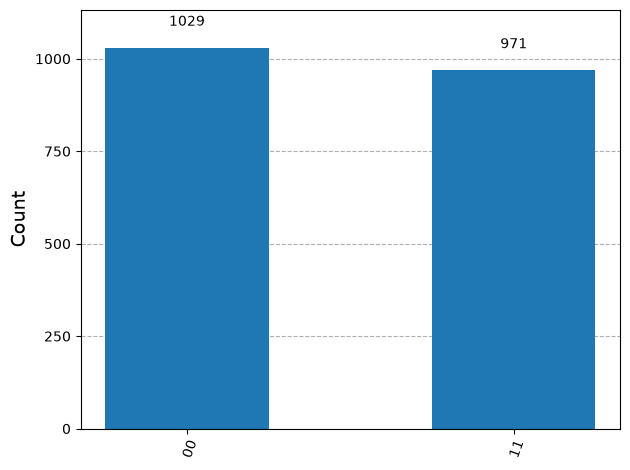

In [14]:
plot_histogram(deep_counts)

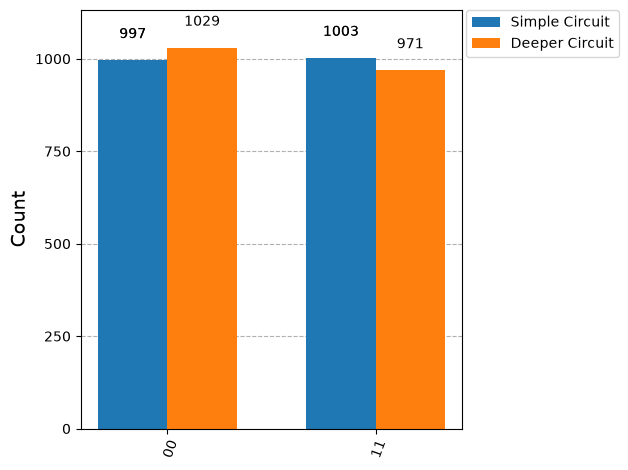

In [15]:
plot_histogram(
    [
        simple_counts,
        deep_counts
    ],
    legend=[
        "Simple Circuit",
        "Deeper Circuit"
    ]
)

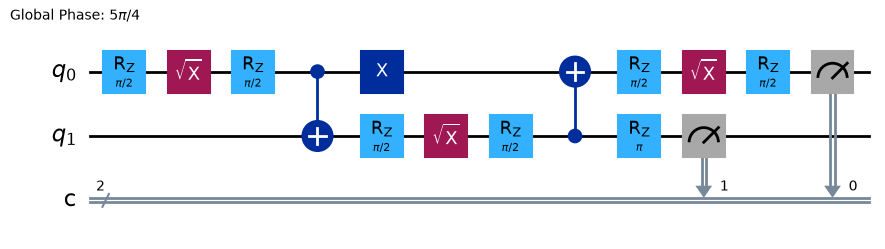

In [16]:
transpiled_circuit = transpile(
    deep_circuit,
    basis_gates=[
        "rz",
        "sx",
        "x",
        "cx"
    ],
    optimization_level=1
)

transpiled_circuit.draw("mpl")

In [17]:
print(
    f"Original depth: "
    f"{deep_circuit.depth()}"
)

print(
    f"Transpiled depth: "
    f"{transpiled_circuit.depth()}"
)

print()

print(
    "Original operations:",
    deep_circuit.count_ops()
)

print(
    "Transpiled operations:",
    transpiled_circuit.count_ops()
)

Original depth: 6
Transpiled depth: 12

Original operations: OrderedDict({'h': 3, 'cx': 2, 'measure': 2, 'x': 1, 'z': 1})
Transpiled operations: OrderedDict({'rz': 7, 'sx': 3, 'cx': 2, 'measure': 2, 'x': 1})


In [18]:
for level in range(4):
    optimized = transpile(
        deep_circuit,
        basis_gates=[
            "rz",
            "sx",
            "x",
            "cx"
        ],
        optimization_level=level
    )

    print(
        f"Optimization level {level}: "
        f"Depth = {optimized.depth()}, "
        f"Instructions = {optimized.size()}"
    )

Optimization level 0: Depth = 12, Instructions = 15
Optimization level 1: Depth = 12, Instructions = 15
Optimization level 2: Depth = 10, Instructions = 14
Optimization level 3: Depth = 10, Instructions = 14


In [19]:
print("QUANTUM CIRCUIT EVALUATION")
print("--------------------------")

print(
    f"Simple circuit depth: "
    f"{simple_circuit.depth()}"
)

print(
    f"Simple circuit instructions: "
    f"{simple_circuit.size()}"
)

print()

print(
    f"Deeper circuit depth: "
    f"{deep_circuit.depth()}"
)

print(
    f"Deeper circuit instructions: "
    f"{deep_circuit.size()}"
)

print()

print(
    "Simple measurement results:",
    simple_counts
)

print(
    "Deeper measurement results:",
    deep_counts
)

QUANTUM CIRCUIT EVALUATION
--------------------------
Simple circuit depth: 3
Simple circuit instructions: 4

Deeper circuit depth: 6
Deeper circuit instructions: 9

Simple measurement results: {'00': 997, '11': 1003}
Deeper measurement results: {'00': 1029, '11': 971}
